# 3 - Selección del modelo

En el notebook 2 vi que los equipos dependen de X, Y y Z en el mismo mes. Después comparé distintos modelos para esa relación y elegí uno.

Lo hice en dos etapas:
1. Probé 8 modelos con validación cruzada para series de tiempo y me quedé con los 3 mejores.
2. A esos 3 los revisé con pruebas más exigentes y elegí el final.

In [1]:
import sys
sys.path.append("..")
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_percentage_error, root_mean_squared_error

from src import datos

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

mensual = pd.read_csv(datos.PROCESSED / "equipos_mensual.csv", index_col="Date", parse_dates=True)
X = mensual[["X", "Y", "Z"]]
equipos = ["Equipo1", "Equipo2"]

## Etapa 1: 8 modelos candidatos

- **Lineales**: regresión lineal, Ridge y Lasso (estos dos con regularización; el valor de alpha lo eligen por validación cruzada).
- **Árboles**: árbol de decisión, Random Forest y Gradient Boosting.
- **Otros**: KNN y SVR.

Usé `TimeSeriesSplit` con 5 cortes de 18 meses cada uno. A diferencia de un k-fold normal, siempre entrena con el pasado y prueba con el futuro, así no hay fuga de información.

In [2]:
def candidatos():
    return {
        "Regresión lineal": LinearRegression(),
        "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 25))),
        "Lasso": make_pipeline(StandardScaler(), LassoCV(cv=TimeSeriesSplit(3), random_state=0)),
        "Árbol de decisión": DecisionTreeRegressor(max_depth=5, random_state=0),
        "Random Forest": RandomForestRegressor(n_estimators=300, random_state=0),
        "Gradient Boosting": GradientBoostingRegressor(random_state=0),
        "KNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
        "SVR": make_pipeline(StandardScaler(), SVR(C=1000, epsilon=1)),
    }


cv = TimeSeriesSplit(n_splits=5, test_size=18)
for i, (tr, te) in enumerate(cv.split(X), 1):
    print(f"corte {i}: entrena hasta {X.index[tr[-1]]:%Y-%m}, prueba {X.index[te[0]]:%Y-%m} a {X.index[te[-1]]:%Y-%m}")

corte 1: entrena hasta 2016-02, prueba 2016-03 a 2017-08
corte 2: entrena hasta 2017-08, prueba 2017-09 a 2019-02
corte 3: entrena hasta 2019-02, prueba 2019-03 a 2020-08
corte 4: entrena hasta 2020-08, prueba 2020-09 a 2022-02
corte 5: entrena hasta 2022-02, prueba 2022-03 a 2023-08


In [3]:
filas = []
for eq in equipos:
    y = mensual[eq]
    for nombre, modelo in candidatos().items():
        mape, rmse = [], []
        for tr, te in cv.split(X):
            modelo.fit(X.iloc[tr], y.iloc[tr])
            pred = modelo.predict(X.iloc[te])
            mape.append(mean_absolute_percentage_error(y.iloc[te], pred) * 100)
            rmse.append(root_mean_squared_error(y.iloc[te], pred))
        filas.append({"equipo": eq, "modelo": nombre, "MAPE": np.mean(mape), "RMSE": np.mean(rmse)})

etapa1 = pd.DataFrame(filas).pivot(index="modelo", columns="equipo", values=["MAPE", "RMSE"])
etapa1[("MAPE", "promedio")] = etapa1["MAPE"].mean(axis=1)
etapa1 = etapa1.sort_values(("MAPE", "promedio"))
etapa1.round(2)

MAPE            RMSE             MAPE
equipo            Equipo1 Equipo2 Equipo1 Equipo2 promedio
modelo                                                    
Lasso                0.29    0.24    1.74    2.63     0.26
Ridge                0.29    0.24    1.75    2.64     0.27
Regresión lineal     0.29    0.24    1.75    2.63     0.27
Gradient Boosting    2.90    2.24   23.25   32.86     2.57
Random Forest        3.87    2.25   27.50   35.74     3.06
Árbol de decisión    4.32    3.08   31.18   40.10     3.70
SVR                  4.41    3.23   40.80   58.80     3.82
KNN                  6.82    2.92   41.29   43.59     4.87

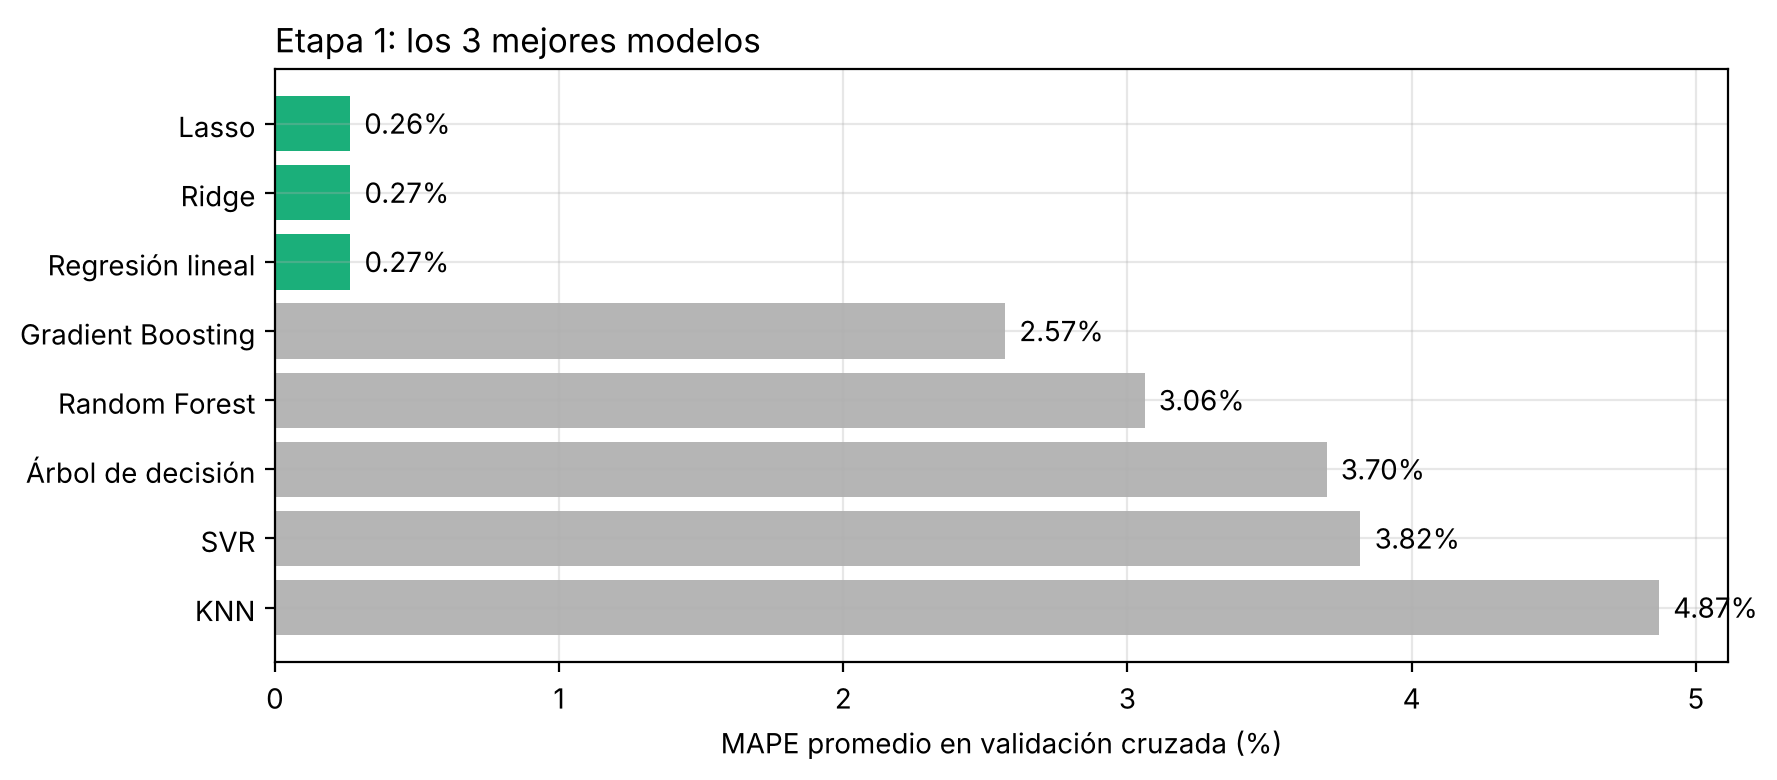

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = etapa1[("MAPE", "promedio")]
colores = ["#1baf7a" if i < 3 else "#b5b5b5" for i in range(len(orden))]
ax.barh(orden.index[::-1], orden.values[::-1], color=colores[::-1])
for i, v in enumerate(orden.values[::-1]):
    ax.text(v + 0.05, i, f"{v:.2f}%", va="center")
ax.set_xlabel("MAPE promedio en validación cruzada (%)")
ax.set_title("Etapa 1: los 3 mejores modelos", loc="left")
plt.tight_layout()
plt.savefig("../reports/figures/03_etapa1_modelos.png", dpi=120)
plt.show()

Los 3 mejores son **regresión lineal, Ridge y Lasso**, con un error de ~0.27%. Los modelos de árboles, KNN y SVR tienen entre 9 y 18 veces más error.

Que los tres primeros sean lineales es consistente con lo que encontré en el notebook 2: la relación entre insumos y equipos es lineal.

Los modelos de árboles tienen un problema de fondo aquí: predicen promedios de lo que vieron al entrenar, así que **no pueden dar un valor más alto que el máximo histórico**. En los últimos cortes (2021-2023) los precios llegaron a niveles que no existían antes y ahí es donde más fallan. Lo mostré en la etapa 2.

## Etapa 2: los 3 finalistas

Revisé tres cosas:
1. **Extrapolación**: entrené hasta 2020 y probé en 2021-2023, el periodo del boom de commodities.
2. **Coeficientes**: si son estables y si se pueden interpretar.
3. **Regularización**: cuánto alpha eligieron Ridge y Lasso.

In [5]:
finalistas = etapa1.index[:3].tolist()
entrena = mensual.loc[:"2020-12"]
prueba = mensual.loc["2021-01":]
print("máximo en entrenamiento:", entrena[equipos].max().round(1).to_dict())
print("máximo en prueba:       ", prueba[equipos].max().round(1).to_dict())

filas = []
predicciones = {}
for eq in equipos:
    for nombre in finalistas + ["Random Forest"]:
        modelo = candidatos()[nombre].fit(entrena[["X", "Y", "Z"]], entrena[eq])
        pred = modelo.predict(prueba[["X", "Y", "Z"]])
        predicciones[(eq, nombre)] = pred
        mape = mean_absolute_percentage_error(prueba[eq], pred) * 100
        filas.append({"modelo": nombre, "equipo": eq, "MAPE": mape})

pd.DataFrame(filas).pivot(index="modelo", columns="equipo", values="MAPE").round(2)

máximo en entrenamiento: {'Equipo1': 610.5, 'Equipo2': 1164.9}
máximo en prueba:        {'Equipo1': 781.6, 'Equipo2': 1499.6}


equipo,Equipo1,Equipo2
modelo,,
Lasso,0.32,0.20
Random Forest,6.56,5.11
Regresión lineal,0.32,0.21
Ridge,0.32,0.20


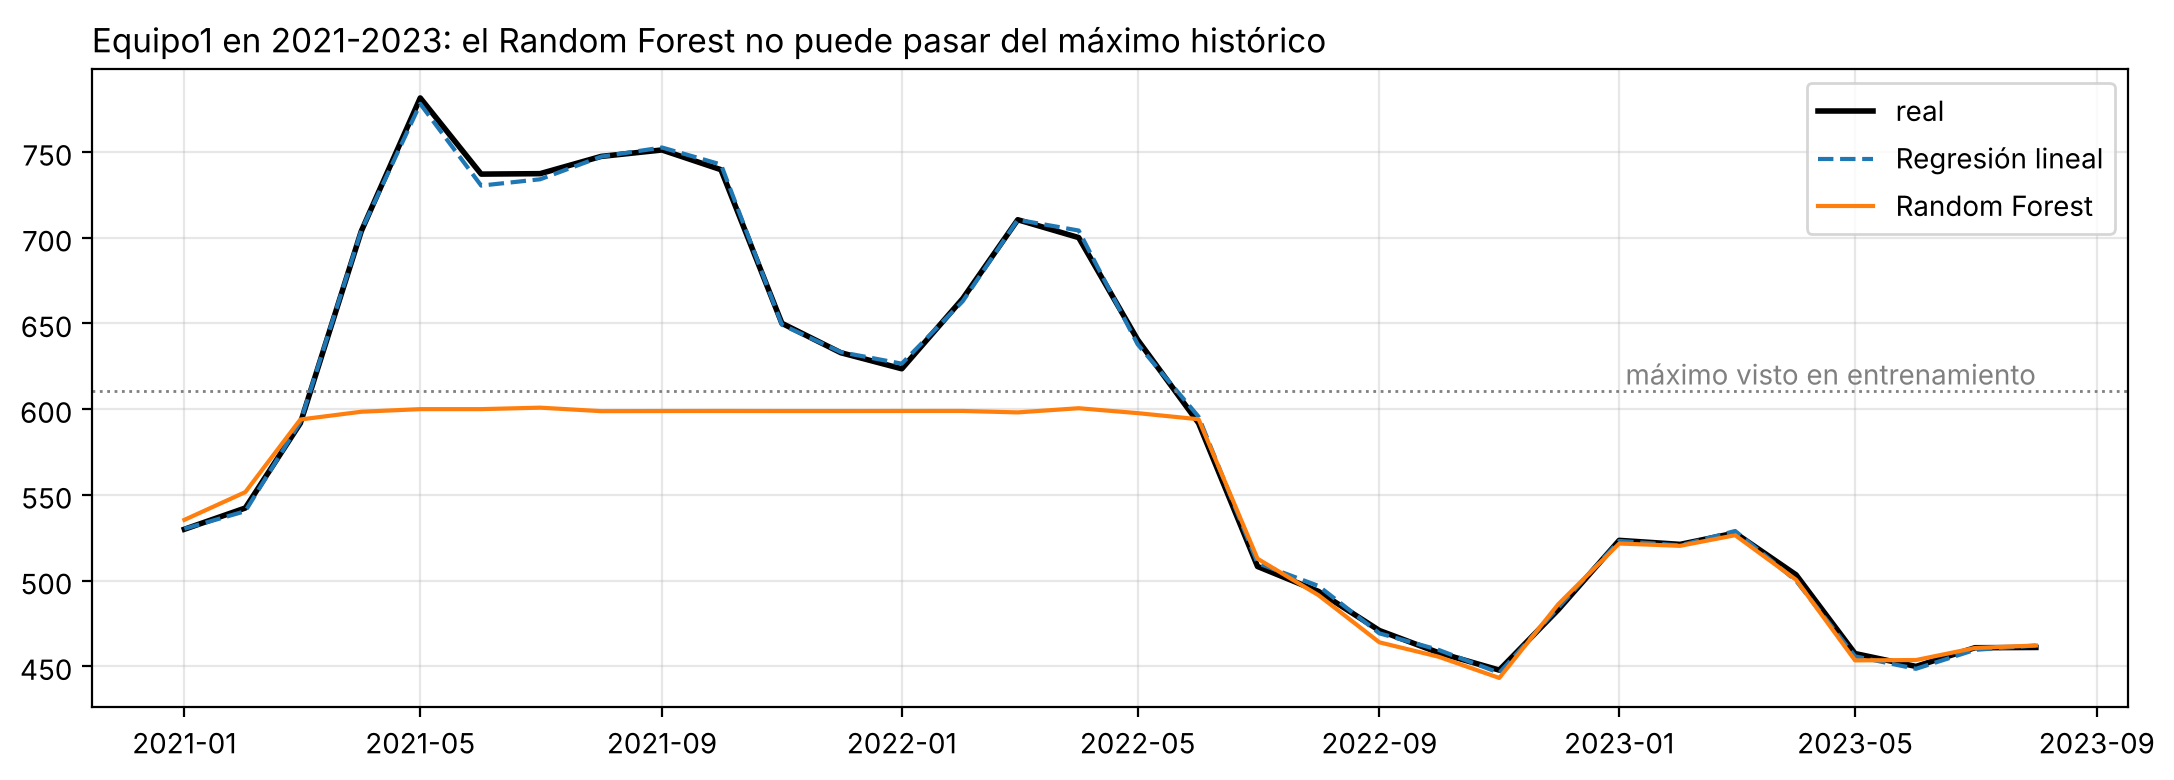

In [6]:
fig, ax = plt.subplots()
ax.plot(prueba.index, prueba["Equipo1"], color="black", lw=2, label="real")
ax.plot(prueba.index, predicciones[("Equipo1", "Regresión lineal")], ls="--", label="Regresión lineal")
ax.plot(prueba.index, predicciones[("Equipo1", "Random Forest")], label="Random Forest")
ax.axhline(entrena["Equipo1"].max(), color="gray", ls=":", lw=1)
ax.text(prueba.index[-1], entrena["Equipo1"].max(), "máximo visto en entrenamiento", ha="right", va="bottom", color="gray")
ax.set_title("Equipo1 en 2021-2023: el Random Forest no puede pasar del máximo histórico", loc="left")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/03_extrapolacion.png", dpi=120)
plt.show()

Los tres lineales mantienen un error de ~0.2-0.3% en el boom. El Random Forest se queda topado en el máximo que vio al entrenar y su error sube a 5-7%.

Ahora los coeficientes. Ridge y Lasso trabajan con datos estandarizados, así que los regresé a la escala original para compararlos:

In [7]:
def coeficientes(modelo):
    if isinstance(modelo, LinearRegression):
        return modelo.coef_, None
    # Ridge y Lasso: regreso los coeficientes a la escala original
    escalador = modelo[0]
    regresion = modelo[-1]
    return regresion.coef_ / escalador.scale_, regresion.alpha_


filas = []
for eq in equipos:
    for nombre in finalistas:
        # coeficientes con todos los datos
        modelo = candidatos()[nombre].fit(X, mensual[eq])
        coef, alpha = coeficientes(modelo)

        # estabilidad: reentreno en cada corte y veo cuánto se mueven los coeficientes
        coef_por_corte = []
        for tr, _ in cv.split(X):
            modelo_corte = candidatos()[nombre].fit(X.iloc[tr], mensual[eq].iloc[tr])
            coef_corte, _ = coeficientes(modelo_corte)
            coef_por_corte.append(coef_corte)
        desv = np.std(coef_por_corte, axis=0)

        filas.append({"equipo": eq, "modelo": nombre, "alpha": alpha,
                      "coef X": coef[0], "coef Y": coef[1], "coef Z": coef[2],
                      "desv. máx. entre cortes": desv.max()})

pd.DataFrame(filas).set_index(["equipo", "modelo"]).round(4)

alpha  coef X  coef Y  coef Z  \
equipo  modelo                                             
Equipo1 Lasso             0.1598  0.1937  0.7996  0.0000   
        Ridge             0.0010  0.1983  0.8005 -0.0001   
        Regresión lineal     NaN  0.1983  0.8006 -0.0001   
Equipo2 Lasso             0.1662  0.3313  0.3351  0.3320   
        Ridge             0.0178  0.3359  0.3355  0.3321   
        Regresión lineal     NaN  0.3358  0.3353  0.3322   

                          desv. máx. entre cortes  
equipo  modelo                                     
Equipo1 Lasso                              0.0055  
        Ridge                              0.0053  
        Regresión lineal                   0.0053  
Equipo2 Lasso                              0.0111  
        Ridge                              0.0117  
        Regresión lineal                   0.0117

- Los tres modelos llegan prácticamente a los mismos coeficientes: 0.2X + 0.8Y para Equipo1 y un tercio de cada insumo para Equipo2.
- Los coeficientes casi no cambian entre cortes (desviación < 0.012), o sea, la relación es estable en el tiempo.
- **Ridge eligió alphas muy pequeños** (el más chico de la lista en Equipo1), así que prácticamente no regulariza. La validación cruzada está diciendo que **no hay sobreajuste que corregir**, lo cual tiene sentido con solo 3 variables y 164 meses.
- **Lasso eliminó Z en Equipo1**, que es la misma conclusión del notebook 2, y no eliminó nada más.

## Modelo elegido: regresión lineal

Los tres finalistas empatan en error, extrapolación y estabilidad. Me quedé con la **regresión lineal** porque:

1. **Es la más simple**: no tiene hiperparámetros que calibrar ni que reajustar cuando lleguen datos nuevos.
2. **Sus coeficientes se leen directo como la receta de cada equipo** y permite inferencia (p-values, intervalos de confianza, la prueba de que los pesos suman 1 del notebook 2). Ridge y Lasso sesgan los coeficientes a propósito, lo cual no tiene sentido si no hay sobreajuste.
3. **Extrapola** a precios que no ha visto, que es justo lo que necesitaba para pronosticar.

Este modelo es el que usé en el notebook 4 para convertir las proyecciones de X, Y y Z en el costo de los equipos.